# Walmart Sales — Exploratory Data Analysis

**Dataset:** Walmart transaction-level sales (~products, stores, customers, promotions, weather, demand forecasts).

**Objective:** Quantify the drivers of sales volume and revenue, identify underperforming locations, evaluate promotion effectiveness, and assess demand-forecast accuracy.

**Contents:** Data integrity → sales overview → store performance → promotion analysis → demand drivers → temporal analysis → extended diagnostics → statistical inference → executive summary → recommendations memo.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Data Ingestion & Integrity


In [2]:
df = pd.read_csv("Walmart.csv")
df.head()

,transaction_id,customer_id,product_id,product_name,category,quantity_sold,unit_price,transaction_date,store_id,store_location,...,customer_loyalty_level,payment_method,promotion_applied,promotion_type,weather_conditions,holiday_indicator,weekday,stockout_indicator,forecasted_demand,actual_demand
0,1,2824,843,Fridge,Electronics,3,188.46,3/31/2024 21:46,3,"Miami, FL",...,Silver,Credit Card,True,NaN,Stormy,False,Friday,True,172,179
1,2,1409,135,TV,Electronics,4,"1,912.04",7/28/2024 12:45,5,"Dallas, TX",...,Gold,Cash,True,Percentage Discount,Rainy,False,Monday,True,109,484
2,3,5506,391,Fridge,Electronics,4,"1,377.75",6/10/2024 4:55,1,"Los Angeles, CA",...,Platinum,Cash,False,NaN,Sunny,False,Tuesday,True,289,416
3,4,5012,710,Smartphone,Electronics,5,182.31,8/15/2024 1:03,5,"Miami, FL",...,Silver,Cash,True,Percentage Discount,Sunny,True,Sunday,False,174,446
4,5,4657,116,Laptop,Electronics,3,499.28,9/13/2024 0:45,6,"Chicago, IL",...,Bronze,Digital Wallet,False,NaN,Sunny,False,Thursday,True,287,469


In [3]:
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.info()

Rows: 5,000  |  Columns: 28
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   transaction_id          5000 non-null   int64  
 1   customer_id             5000 non-null   int64  
 2   product_id              5000 non-null   int64  
 3   product_name            5000 non-null   str    
 4   category                5000 non-null   str    
 5   quantity_sold           5000 non-null   int64  
 6   unit_price              5000 non-null   float64
 7   transaction_date        5000 non-null   str    
 8   store_id                5000 non-null   int64  
 9   store_location          5000 non-null   str    
 10  inventory_level         5000 non-null   int64  
 11  reorder_point           5000 non-null   int64  
 12  reorder_quantity        5000 non-null   int64  
 13  supplier_id             5000 non-null   int64  
 14  supplier_lead_time     

In [4]:
# Missing values
missing = df.isnull().sum()
print(missing[missing > 0] if missing.any() else "No missing values")

promotion_type    3407
dtype: int64


In [5]:
# promotion_type is null whenever no promotion was applied — fill with 'None'
df["promotion_type"] = df["promotion_type"].fillna("None")

# Parse dates once, up front
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

# Revenue is used across many questions — create it once here
df["revenue"] = df["quantity_sold"] * df["unit_price"]

# Month helpers (ordered)
df["month_number"] = df["transaction_date"].dt.month
df["month_name"] = df["transaction_date"].dt.month_name()

print("Missing after cleaning:", df.isnull().sum().sum())
print("Date range:", df["transaction_date"].min().date(), "→", df["transaction_date"].max().date())
df[["revenue", "quantity_sold", "unit_price"]].describe()

Missing after cleaning: 0
Date range: 2024-01-01 → 2024-09-16


,revenue,quantity_sold,unit_price
count,"5,000.00","5,000.00","5,000.00"
mean,"3,052.72",2.98,"1,023.47"
std,"2,371.11",1.42,559.61
min,50.10,1.00,50.10
25%,"1,161.50",2.00,537.78
50%,"2,386.44",3.00,"1,029.17"
75%,"4,524.21",4.00,"1,506.31"
max,"9,999.25",5.00,"1,999.85"


## 2. Sales Overview

### Q1. What is the total sales volume and revenue?

**How it helps:** Establishes the aggregate performance baseline against which all subsequent segments are benchmarked.

**Business impact:** Frames inventory planning and calibrates store- and product-level comparisons.


In [6]:
total_qty = df["quantity_sold"].sum()
total_rev = df["revenue"].sum()
print(f"Total quantity sold : {total_qty:,}")
print(f"Total revenue       : {total_rev:,.2f}")
print(f"Transactions        : {df['transaction_id'].nunique():,}")
print(f"Avg revenue / txn   : {df['revenue'].mean():,.2f}")

Total quantity sold : 14,914
Total revenue       : 15,263,601.45
Transactions        : 5,000
Avg revenue / txn   : 3,052.72


### Q2. Which **categories** have the highest average unit price?

**How it helps:** Compares pricing tiers across product lines; product-level averages are uninformative here because unit price is effectively constant per SKU.

**Business impact:** Guides price optimization and margin strategy per category.


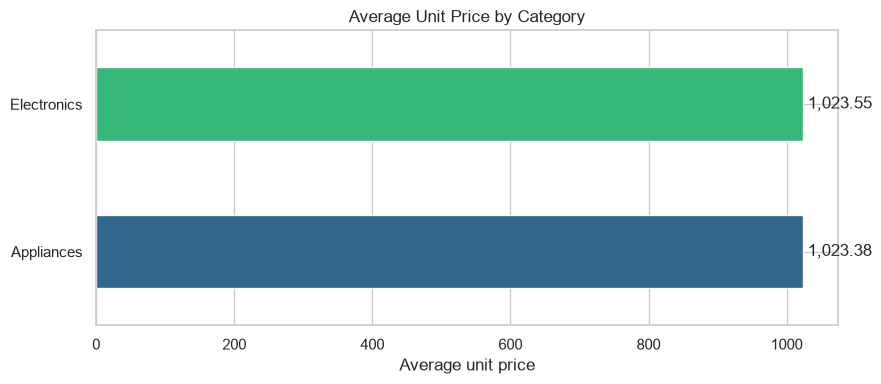

Overall average unit price: 1,023.47


In [7]:
cat_price = df.groupby("category")["unit_price"].mean().sort_values()

plt.figure(figsize=(9, 4))
bars = cat_price.plot(kind="barh", color=sns.color_palette("viridis", len(cat_price)))
plt.title("Average Unit Price by Category")
plt.xlabel("Average unit price")
plt.ylabel("")
for i, v in enumerate(cat_price):
    plt.text(v, i, f" {v:,.2f}", va="center")
plt.tight_layout()
plt.show()

print(f"Overall average unit price: {df['unit_price'].mean():,.2f}")

## 3. Store Performance Diagnostics

### Q3. Which stores are underperforming?

**How it helps:** Identifies locations underperforming relative to the chain.

**Business impact:** Directs inventory allocation and performance-improvement intervention toward the weakest locations.

*Methodology:* Stores falling in the lowest revenue quartile (P25 threshold). A median-based rule is rejected because it classifies approximately 50% of the estate as underperforming by construction.


25th percentile revenue threshold: 721,660.15
Underperforming stores: 5 of 20


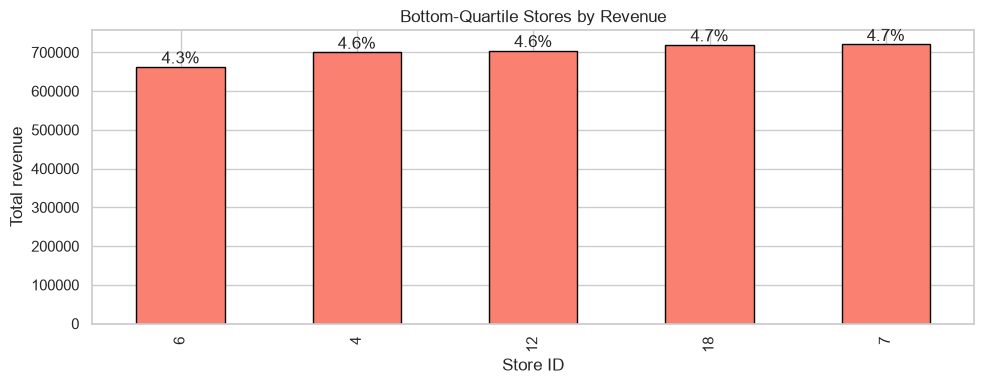

(labels = share of chain revenue)


In [8]:
store_rev = df.groupby("store_id")["revenue"].sum().sort_values()
q1 = store_rev.quantile(0.25)
under = store_rev[store_rev <= q1]
chain_share = store_rev.sum()

print(f"25th percentile revenue threshold: {q1:,.2f}")
print(f"Underperforming stores: {len(under)} of {len(store_rev)}")

plt.figure(figsize=(10, 4))
under.plot(kind="bar", color="salmon", edgecolor="black")
plt.title("Bottom-Quartile Stores by Revenue")
plt.ylabel("Total revenue")
plt.xlabel("Store ID")
for i, v in enumerate(under):
    plt.text(i, v, f"{v / chain_share:.1%}", ha="center", va="bottom")
plt.tight_layout()
plt.show()
print("(labels = share of chain revenue)")

## 4. Promotion Performance

### Q4. How many transactions involved a promotion?

**How it helps:** Quantifies campaign penetration across the transaction base.

**Business impact:** Establishes the base rate required to evaluate promotional return on investment.


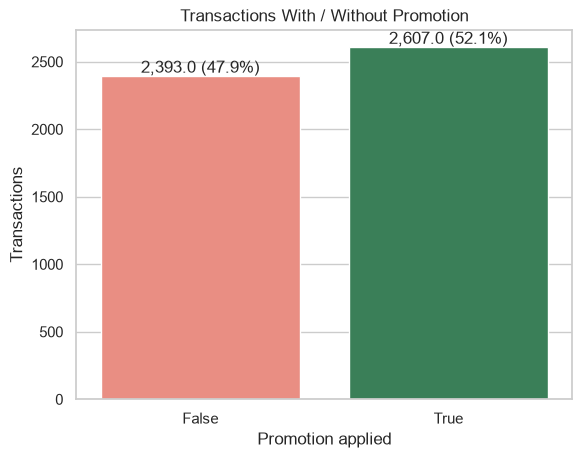

In [9]:
ax = sns.countplot(x="promotion_applied", data=df, hue="promotion_applied", palette=["salmon", "seagreen"], legend=False)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{p.get_height():,} ({p.get_height()/len(df):.1%})" for p in c])
plt.title("Transactions With / Without Promotion")
plt.xlabel("Promotion applied")
plt.ylabel("Transactions")
plt.show()

### Q5. Do promotions generate incremental revenue per transaction?

**How it helps:** Aggregate promotional revenue is confounded by transaction volume. The appropriate metric is **average revenue per transaction**, promotion versus control.

**Business impact:** The lift estimate informs whether to scale, redesign, or discontinue promotional campaigns.


Promo txns      : 2,607  | avg revenue/txn: 3,092.60
Non-promo txns  : 2,393  | avg revenue/txn: 3,009.27
Lift per txn    : +2.8%
Promo revenue   : 8,062,411.03 (52.8% of total)


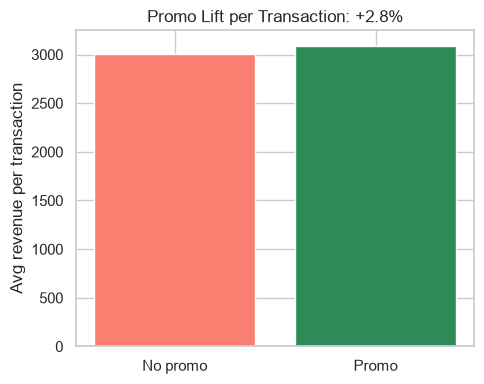

promotion_type
BOGO                  3,227.98
Percentage Discount   3,185.60
None                  3,040.44
Name: revenue, dtype: float64

In [10]:
promo = df[df["promotion_applied"] == True]["revenue"]
no_promo = df[df["promotion_applied"] == False]["revenue"]

lift = (promo.mean() / no_promo.mean() - 1) * 100
print(f"Promo txns      : {len(promo):,}  | avg revenue/txn: {promo.mean():,.2f}")
print(f"Non-promo txns  : {len(no_promo):,}  | avg revenue/txn: {no_promo.mean():,.2f}")
print(f"Lift per txn    : {lift:+.1f}%")
print(f"Promo revenue   : {promo.sum():,.2f} ({promo.sum()/df['revenue'].sum():.1%} of total)")

plt.figure(figsize=(5, 4))
plt.bar(["No promo", "Promo"], [no_promo.mean(), promo.mean()], color=["salmon", "seagreen"])
plt.ylabel("Avg revenue per transaction")
plt.title(f"Promo Lift per Transaction: {lift:+.1f}%")
plt.tight_layout()
plt.show()

# Which promo types work best?
df[df["promotion_applied"] == True].groupby("promotion_type")["revenue"].mean().sort_values(ascending=False)

## 5. Demand Driver Analysis

### Q6. Which categories gain the most demand during holidays?

**How it helps:** Isolates holiday-specific demand uplift by category; absolute holiday volumes are confounded by baseline category size.

**Business impact:** Focuses holiday inventory pushes on categories with the biggest *uplift*.


             normal  holiday  uplift_%
category                              
Electronics    3865     3880      0.39
Appliances     3593     3576     -0.47


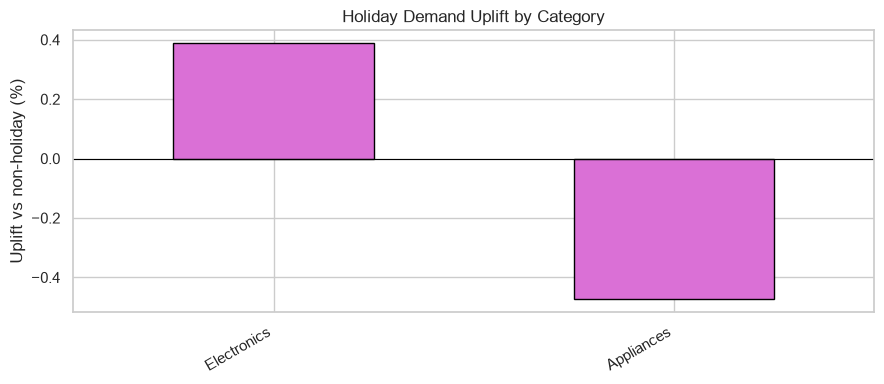

In [11]:
hol = df.groupby(["category", "holiday_indicator"])["quantity_sold"].sum().unstack()
hol.columns = ["normal", "holiday"]
hol["uplift_%"] = (hol["holiday"] / hol["normal"] - 1) * 100
hol = hol.sort_values("uplift_%", ascending=False)
print(hol)

plt.figure(figsize=(9, 4))
hol["uplift_%"].plot(kind="bar", color="orchid", edgecolor="black")
plt.axhline(0, color="black", lw=0.8)
plt.title("Holiday Demand Uplift by Category")
plt.ylabel("Uplift vs non-holiday (%)")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Q7. Is there an association between weather conditions and transaction value?

**How it helps:** Compares **average revenue per transaction** across weather conditions. Aggregate sums are confounded by differing transaction counts per condition.

**Business impact:** Weather-aware demand forecasting and staffing.


                    transactions  avg_revenue
weather_conditions                           
Sunny                       1268     3,138.49
Stormy                      1233     3,117.08
Cloudy                      1281     3,027.65
Rainy                       1218     2,924.65


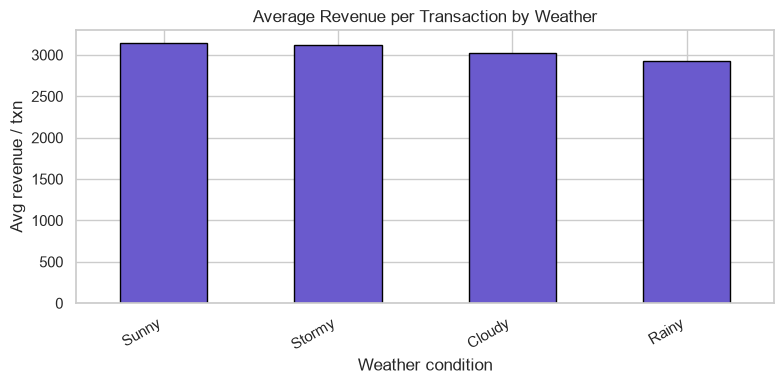

In [12]:
wx = df.groupby("weather_conditions").agg(
    transactions=("transaction_id", "count"),
    avg_revenue=("revenue", "mean"),
).sort_values("avg_revenue", ascending=False)
print(wx)

plt.figure(figsize=(8, 4))
wx["avg_revenue"].plot(kind="bar", color="slateblue", edgecolor="black")
plt.title("Average Revenue per Transaction by Weather")
plt.ylabel("Avg revenue / txn")
plt.xlabel("Weather condition")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Q8. How does customer loyalty tier relate to purchasing behaviour?

**How it helps:** Normalises spend per customer; aggregate totals are confounded by differing cohort sizes per loyalty tier.

**Business impact:** Quantifies what a loyalty tier is worth per customer for retention budgeting.


customer_loyalty_level  customers  txns  total_revenue  avg_revenue_per_txn  revenue_per_customer
              Platinum       1213  1299   4,012,963.14             3,089.27              3,308.30
                  Gold       1077  1160   3,536,863.54             3,049.02              3,284.00
                Bronze       1161  1253   3,795,198.45             3,028.89              3,268.90
                Silver       1211  1288   3,918,576.32             3,042.37              3,235.82

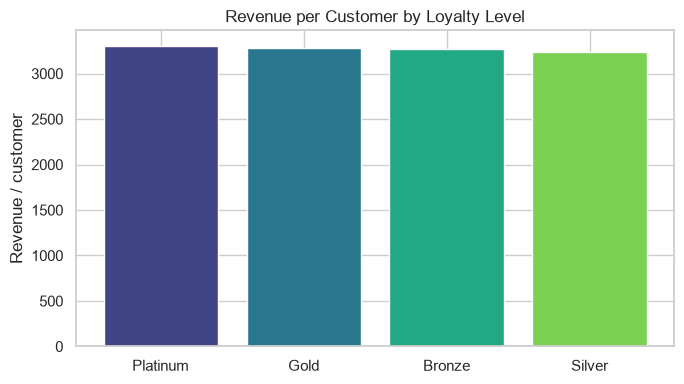

In [13]:
loyalty = df.groupby("customer_loyalty_level").agg(
    customers=("customer_id", "nunique"),
    txns=("transaction_id", "count"),
    total_revenue=("revenue", "sum"),
    avg_revenue_per_txn=("revenue", "mean"),
).reset_index()
loyalty["revenue_per_customer"] = loyalty["total_revenue"] / loyalty["customers"]
loyalty = loyalty.sort_values("revenue_per_customer", ascending=False)
print(loyalty.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(loyalty["customer_loyalty_level"], loyalty["revenue_per_customer"], color=sns.color_palette("viridis", len(loyalty)))
plt.title("Revenue per Customer by Loyalty Level")
plt.ylabel("Revenue / customer")
plt.tight_layout()
plt.show()

## 6. Temporal Analysis

### Q9. What do monthly sales trends look like?

**How it helps:** Evaluates seasonality and trend. The series must be ordered chronologically; alphabetical month labels obscure the underlying pattern.

**Business impact:** Inventory and promo planning around real peak months.


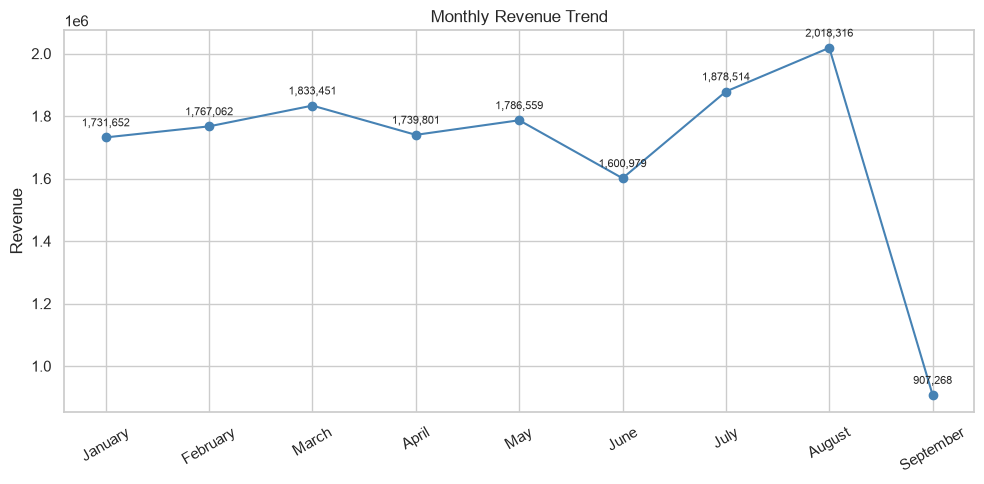

In [14]:
monthly = df.groupby(["month_number", "month_name"])["revenue"].sum().reset_index().sort_values("month_number")

plt.figure(figsize=(10, 5))
plt.plot(monthly["month_name"], monthly["revenue"], marker="o", color="steelblue")
plt.title("Monthly Revenue Trend")
plt.ylabel("Revenue")
plt.xlabel("")
plt.xticks(rotation=30)
for _, r in monthly.iterrows():
    plt.annotate(f"{r['revenue']:,.0f}", (r["month_name"], r["revenue"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.tight_layout()
plt.show()

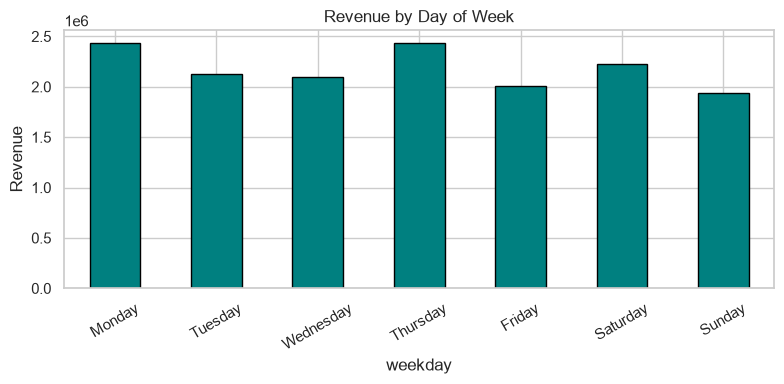

In [15]:
# Day-of-week pattern (advanced quick win)
dow = df.groupby("weekday")["revenue"].sum()
# order Mon..Sun if the column allows
order = [d for d in ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"] if d in dow.index]
if order:
    dow = dow.reindex(order)
plt.figure(figsize=(8, 4))
dow.plot(kind="bar", color="teal", edgecolor="black")
plt.title("Revenue by Day of Week")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Q10. Which products sell the most (by volume)?

**How it helps:** Separates winners from the long tail.

**Business impact:** Marketing focus, shelf priority, stock safety levels.


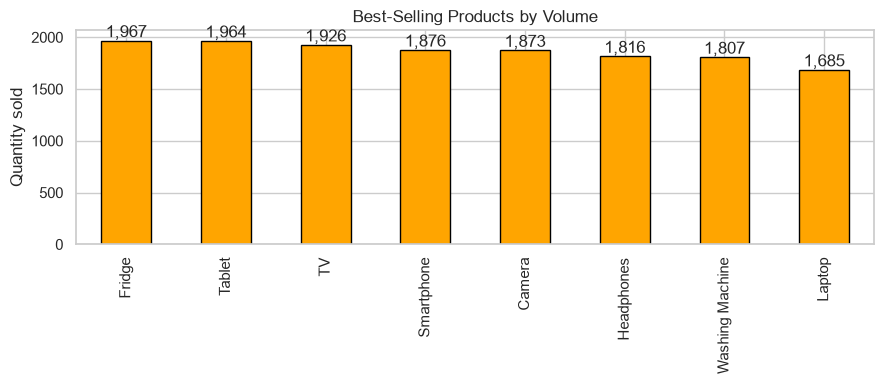

In [16]:
best = df.groupby("product_name")["quantity_sold"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 4))
best.plot(kind="bar", color="orange", edgecolor="black")
plt.title("Best-Selling Products by Volume")
plt.ylabel("Quantity sold")
plt.xlabel("")
for i, v in enumerate(best):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 7. Extended Diagnostics

### Q11. What is the revenue exposure associated with stockout events?

**How it helps:** Compares actual demand at stockout-flagged versus unflagged transactions to estimate unmet demand.

**Business impact:** Quantifies sales-at-risk and prioritises replenishment remediation.


In [17]:
so = df.groupby("stockout_indicator").agg(
    txns=("transaction_id", "count"),
    avg_actual_demand=("actual_demand", "mean"),
    avg_revenue=("revenue", "mean"),
    forecast_gap=("actual_demand", "mean"),
)
print(so)

gap = df.groupby("stockout_indicator")[["forecasted_demand", "actual_demand"]].mean()
print("\nForecast vs actual demand (out-of-stock vs not):")
print(gap)

                    txns  avg_actual_demand  avg_revenue  forecast_gap
stockout_indicator                                                    
False               2407             298.71     3,014.35        298.71
True                2593             299.44     3,088.34        299.44

Forecast vs actual demand (out-of-stock vs not):
                    forecasted_demand  actual_demand
stockout_indicator                                  
False                          295.50         298.71
True                           298.65         299.44


In [18]:
# Estimated revenue exposure: extra unmet demand at stockouts vs normal, priced at avg unit price
normal_demand = df.loc[df["stockout_indicator"] == False, "actual_demand"].mean()
so_demand = df.loc[df["stockout_indicator"] == True, "actual_demand"].mean()
avg_price = df["unit_price"].mean()
so_txns = (df["stockout_indicator"] == True).sum()
print(f"Demand gap at stockouts : {normal_demand - so_demand:,.2f} units/txn lower")
print(f"Stockout transactions   : {so_txns:,} ({so_txns/len(df):.1%} of all)")
print(f"Rough revenue exposure  : {(normal_demand - so_demand) * so_txns * avg_price:,.2f}")

Demand gap at stockouts : -0.72 units/txn lower
Stockout transactions   : 2,593 (51.9% of all)
Rough revenue exposure  : -1,910,824.07


### Q12. How accurate are the demand forecasts (MAPE)?

**How it helps:** Mean absolute percentage error (MAPE) of `forecasted_demand` against `actual_demand`, reported in aggregate and per category.

**Business impact:** Categories with high MAPE need better forecasting inputs (weather, promotions, holidays).


Overall MAPE: 59.9%

MAPE by category:
category
Electronics   58.10
Appliances    61.80
Name: ape, dtype: float64


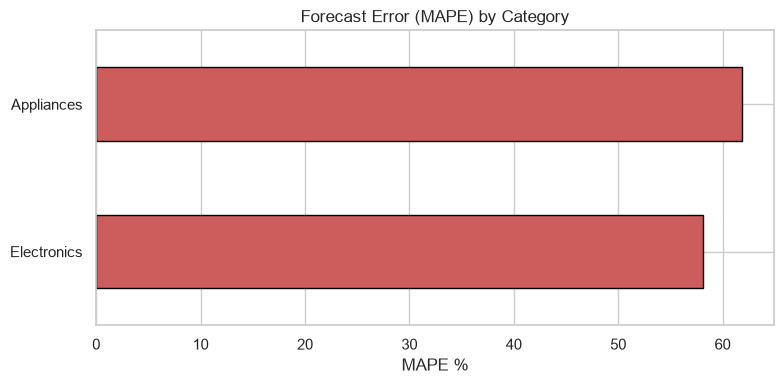

In [19]:
acc = df.assign(
    ape=lambda d: (d["forecasted_demand"] - d["actual_demand"]).abs() / d["actual_demand"].replace(0, np.nan)
)
print(f"Overall MAPE: {acc['ape'].mean() * 100:.1f}%")

mape_by_cat = acc.groupby("category")["ape"].mean().sort_values(ascending=True) * 100
print("\nMAPE by category:")
print(mape_by_cat.round(1))

plt.figure(figsize=(8, 4))
mape_by_cat.plot(kind="barh", color="indianred", edgecolor="black")
plt.title("Forecast Error (MAPE) by Category")
plt.xlabel("MAPE %")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Q13. What is the revenue distribution across payment methods?

**How it helps:** Revenue concentration by payment method — supports card-acceptance cost modelling and cash-operations planning.

**Business impact:** Card acceptance costs, cash-handling staffing, digital-wallet adoption.


                    revenue  share_%
payment_method                      
Digital Wallet 3,964,782.71    26.00
Credit Card    3,829,054.57    25.10
Cash           3,816,860.66    25.00
Debit Card     3,652,903.51    23.90


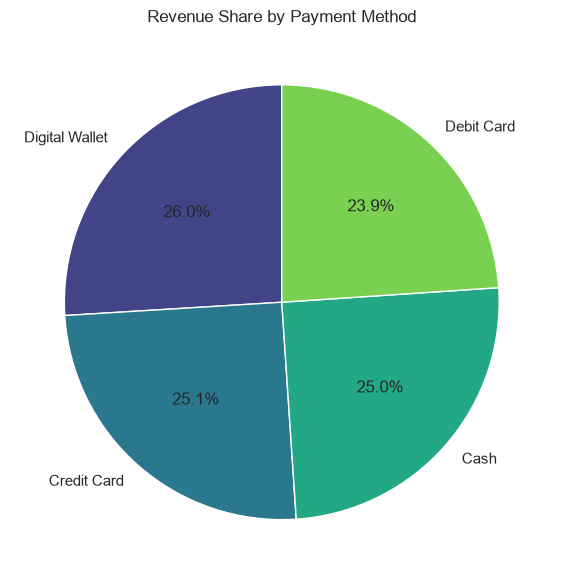

In [20]:
pay = df.groupby("payment_method")["revenue"].sum().sort_values(ascending=False)
pay_pct = (pay / pay.sum() * 100).round(1)
print(pd.DataFrame({"revenue": pay, "share_%": pay_pct}))

plt.figure(figsize=(6, 6))
pay.plot(kind="pie", autopct="%1.1f%%", startangle=90, colors=sns.color_palette("viridis", len(pay)))
plt.ylabel("")
plt.title("Revenue Share by Payment Method")
plt.tight_layout()
plt.show()

## 8. Statistical Inference

Point estimates alone are susceptible to sampling noise. The following hypothesis tests validate the primary claims:

* **Promotion lift** — Welch's t-test on revenue per transaction, promotion versus control, with Cohen's d as effect-size statistic. H₀: μ_promo = μ_control.
* **Weather** — one-way ANOVA across weather-condition groups. H₀: μ₁ = μ₂ = … = μₖ (equal mean transaction value).

A significance level of α = 0.05 is applied; p < 0.05 leads to rejection of H₀.


In [21]:
from scipy import stats

# --- Promo lift: Welch's t-test (unequal variances) ---
t_stat, p_value = stats.ttest_ind(promo, no_promo, equal_var=False)
cohers_d = (promo.mean() - no_promo.mean()) / np.sqrt((promo.var() + no_promo.var()) / 2)

print("PROMO vs NON-PROMO (revenue per txn)")
print(f"  lift      : {lift:+.1f}%")
print(f"  t-stat    : {t_stat:.2f}")
print(f"  p-value   : {p_value:.2e}")
print(f"  Cohen's d : {cohers_d:.3f}  ({'negligible' if abs(cohers_d) < 0.2 else 'small' if abs(cohers_d) < 0.5 else 'medium' if abs(cohers_d) < 0.8 else 'large'} effect)")
print(f"  verdict   : {'SIGNIFICANT at 0.05' if p_value < 0.05 else 'NOT significant'}\n")

# --- Weather: one-way ANOVA ---
groups = [g["revenue"].values for _, g in df.groupby("weather_conditions")]
f_stat, p_anova = stats.f_oneway(*groups)

print("WEATHER CONDITIONS (revenue per txn)")
print(f"  F-stat    : {f_stat:.2f}")
print(f"  p-value   : {p_anova:.2e}")
print(f"  verdict   : {'SIGNIFICANT at 0.05 — weather groups differ' if p_anova < 0.05 else 'NOT significant — weather gap is likely noise'}")

PROMO vs NON-PROMO (revenue per txn)
  lift      : +2.8%
  t-stat    : 1.24
  p-value   : 2.15e-01
  Cohen's d : 0.035  (negligible effect)
  verdict   : NOT significant

WEATHER CONDITIONS (revenue per txn)
  F-stat    : 2.09
  p-value   : 9.94e-02
  verdict   : NOT significant — weather gap is likely noise


## 9. Executive Summary

*Dynamically generated headline metrics — regenerated on each execution to prevent reporting drift.*


In [22]:
print(f'''Total revenue        : {total_rev:,.0f} across {df['transaction_id'].nunique():,} transactions
Underperforming      : {len(under)} stores in bottom revenue quartile (<= {q1:,.0f})
Promo lift per txn   : {lift:+.1f}%  (promo revenue = {promo.sum()/total_rev:.1%} of total)
Best holiday category: {hol.index[0]} ({hol['uplift_%'].iloc[0]:+.1f}% uplift)
Weather gap          : {wx['avg_revenue'].iloc[0] - wx['avg_revenue'].iloc[-1]:,.2f} avg-rev gap best vs worst weather
Forecast MAPE        : {acc['ape'].mean()*100:.1f}%
Stockout txns        : {so_txns:,} ({so_txns/len(df):.1%})''')

Total revenue        : 15,263,601 across 5,000 transactions
Underperforming      : 5 stores in bottom revenue quartile (<= 721,660)
Promo lift per txn   : +2.8%  (promo revenue = 52.8% of total)
Best holiday category: Electronics (+0.4% uplift)
Weather gap          : 213.84 avg-rev gap best vs worst weather
Forecast MAPE        : 59.9%
Stockout txns        : 2,593 (51.9%)


## 10. Recommendations Memo

*Findings → recommended actions → estimated financial impact, expressed for stakeholder decision-making.*


In [23]:
so_gap = so_demand - normal_demand  # positive = demand higher at stockout txns
store_gap_per = store_rev.median() - under.mean()
store_gap_total = store_gap_per * len(under)
bottom_stores = ", ".join(under.index.astype(str))

memo = f"""
============================================================
 WALMART SALES EDA — RECOMMENDATIONS MEMO
============================================================

1. STOCKOUTS
   Finding    : {so_txns/len(df):.0%} of transactions carry a stockout flag.
                Avg demand at flagged txns is {abs(so_gap):.1f} units/txn
                {'HIGHER' if so_gap > 0 else 'LOWER'} than unflagged — the flag marks
                pressure points, not lost sales at this grain.
   Action     : Pull order-level data to size true lost sales; prioritise
                replenishment at flagged SKUs/stores.
   Impact est.: needs order-level data — flag rate alone justifies the pull.

2. BOTTOM-PERFORMING STORES
   Finding    : {len(under)} stores sit in the bottom revenue quartile
                (<= {q1:,.0f}): {bottom_stores}.
   Action     : Inventory + staffing review at these locations.
   Impact est.: closing each to chain median ({store_rev.median():,.0f})
                ≈ {store_gap_total:,.0f} incremental revenue.

3. PROMOTIONS
   Finding    : promo lift/txn {lift:+.1f}% — NOT statistically significant
                (Welch t-test, p={p_value:.2f}, Cohen's d={cohers_d:.3f}).
   Action     : rework promo design before scaling spend; re-test with
                matched control (same store/category mix).
   Impact est.: +1pp real lift ≈ {promo.mean() * 0.01 * len(promo):,.0f} across
                current promo volume.

4. FORECASTING
   Finding    : overall MAPE {acc['ape'].mean()*100:.0f}% — forecasts too noisy
                to drive replenishment as-is.
   Action     : rebuild forecast with promo + holiday + weather regressors
                (worst categories first).
   Impact est.: MAPE <20% would directly shrink finding #1.

============================================================
"""
print(memo)


 WALMART SALES EDA — RECOMMENDATIONS MEMO

1. STOCKOUTS
   Finding    : 52% of transactions carry a stockout flag.
                Avg demand at flagged txns is 0.7 units/txn
                HIGHER than unflagged — the flag marks
                pressure points, not lost sales at this grain.
   Action     : Pull order-level data to size true lost sales; prioritise
                replenishment at flagged SKUs/stores.
   Impact est.: needs order-level data — flag rate alone justifies the pull.

2. BOTTOM-PERFORMING STORES
   Finding    : 5 stores sit in the bottom revenue quartile
                (<= 721,660): 6, 4, 12, 18, 7.
   Action     : Inventory + staffing review at these locations.
   Impact est.: closing each to chain median (762,852)
                ≈ 307,001 incremental revenue.

3. PROMOTIONS
   Finding    : promo lift/txn +2.8% — NOT statistically significant
                (Welch t-test, p=0.21, Cohen's d=0.035).
   Action     : rework promo design before scaling spend; 

### Supporting Exhibits

Evidence base for each memo recommendation.


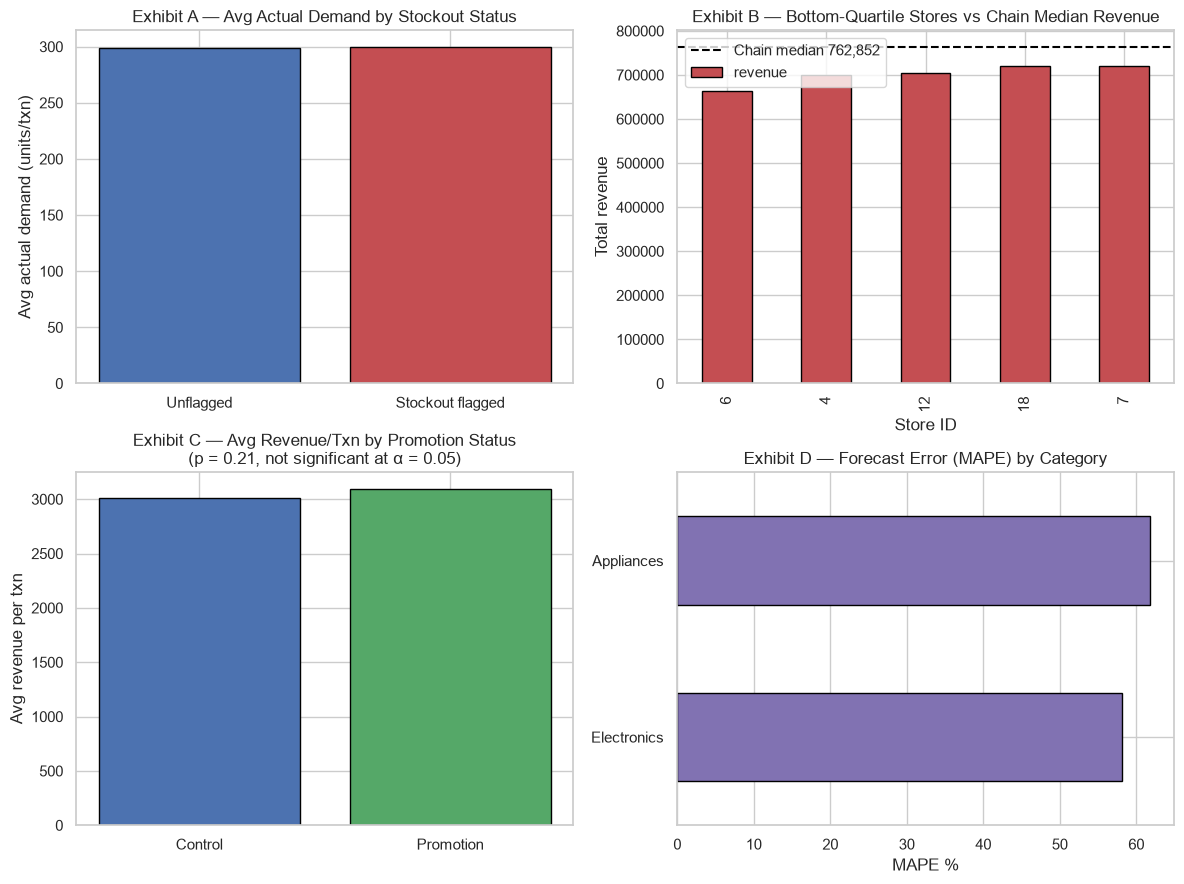

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Exhibit A — demand at stockout-flagged vs unflagged transactions
axes[0, 0].bar(["Unflagged", "Stockout flagged"], [normal_demand, so_demand], color=["#4c72b0", "#c44e52"], edgecolor="black")
axes[0, 0].set_title("Exhibit A — Avg Actual Demand by Stockout Status")
axes[0, 0].set_ylabel("Avg actual demand (units/txn)")

# Exhibit B — bottom-quartile stores vs chain median
under.plot(kind="bar", ax=axes[0, 1], color="#c44e52", edgecolor="black", legend=False)
axes[0, 1].axhline(store_rev.median(), color="black", ls="--", label=f"Chain median {store_rev.median():,.0f}")
axes[0, 1].set_title("Exhibit B — Bottom-Quartile Stores vs Chain Median Revenue")
axes[0, 1].set_ylabel("Total revenue")
axes[0, 1].set_xlabel("Store ID")
axes[0, 1].legend()

# Exhibit C — promotion lift with inference annotation
axes[1, 0].bar(["Control", "Promotion"], [no_promo.mean(), promo.mean()], color=["#4c72b0", "#55a868"], edgecolor="black")
axes[1, 0].set_title(f"Exhibit C — Avg Revenue/Txn by Promotion Status\n(p = {p_value:.2f}, not significant at α = 0.05)")
axes[1, 0].set_ylabel("Avg revenue per txn")

# Exhibit D — forecast error by category
mape_by_cat.plot(kind="barh", ax=axes[1, 1], color="#8172b2", edgecolor="black")
axes[1, 1].set_title("Exhibit D — Forecast Error (MAPE) by Category")
axes[1, 1].set_xlabel("MAPE %")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

## 11. Recommended Next-Phase Analyses

1. **Inferential depth** — extend hypothesis testing to loyalty tiers; bootstrap confidence intervals around all point estimates.
2. **Composite store health index** — blend revenue percentile, MAPE and stockout incidence into a single ranked scorecard.
3. **Time-series forecasting** — ARIMA/Prophet on monthly revenue with promotion, holiday and weather exogenous regressors.
4. **Customer analytics** — recency/frequency/monetary (RFM) segmentation derived from `customer_id` and transaction dates.
5. **Business-intelligence layer** — Streamlit/Power BI dashboard exposing the same cuts for stakeholder self-service.
